# ResNet 1D per time series
Blocchi residuali 1D applicati direttamente ai tre assi raw (non ResNet per immagini). Normalizzazione stimata solo nel training fold, pooling consapevole delle lunghezze e early stopping su validation interna. Dipendenza: PyTorch.

In [1]:
import config as cfg, utils, advanced_models as adv
utils.print_versions()
adv.print_versions()
utils.print_config()
print('canali:', cfg.QUICK_TORCH_CHANNELS if cfg.QUICK_TEST else cfg.TORCH_CHANNELS)
MODEL = 'resnet1d'

Python      : 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
numpy       : 2.5.4
pandas      : 3.0.6
scipy       : 1.18.1
sklearn     : 1.9.1
catboost    : 1.2.10
matplotlib  : 3.11.2
natsort     : 8.4.0
tqdm        : 4.70.1
Python: 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
xgboost: 3.4.1
sktime: 1.2.0
torch: 2.14.1
SEED=89  N_SPLITS=10  CV_MODE=stratified  QUICK_TEST=False
FALL_CLASSES: {'UniMiB': [9, 10, 11, 12, 13, 14, 15, 16], 'UniZgFall': [5, 6, 7]}
canali: (32, 64, 128)


## Cross-validation, metriche e predizioni

In [2]:
adv.run_all(MODEL)

[resnet1d | UniZgFall | raw] X=(468, 3, 5150), classi=10, CV=stratified, fold=10
Parametri: max_epochs=30, batch_size=64, lr=0.001, weight_decay=0.0001


resnet1d|UniZgFall:   0%|          | 0/10 [00:00<?, ?it/s]

[resnet1d | UniZgFall | raw | fold 1/10] train su 421 esempi, test su 47
fit in corso...


/home/agrume/Desktop/projects/thesis/fall_detection_ml/advanced_models.py:296: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  y_tensor = torch.from_numpy(np.asarray(y, dtype=np.int64))


  epoch 1/30: train_loss=3.9069, val_loss=2.1134, val_acc=0.3647
  epoch 2/30: train_loss=1.8317, val_loss=1.8964, val_acc=0.4471
  epoch 3/30: train_loss=1.4721, val_loss=1.6563, val_acc=0.5529
  epoch 4/30: train_loss=1.2329, val_loss=1.4578, val_acc=0.6000
  epoch 5/30: train_loss=0.9933, val_loss=1.2210, val_acc=0.6588
  epoch 6/30: train_loss=0.8461, val_loss=1.0557, val_acc=0.7176
  epoch 7/30: train_loss=0.6888, val_loss=0.9447, val_acc=0.7529
  epoch 8/30: train_loss=0.6284, val_loss=0.8340, val_acc=0.7412
  epoch 9/30: train_loss=0.5007, val_loss=0.7795, val_acc=0.8000
  epoch 10/30: train_loss=0.4503, val_loss=0.7023, val_acc=0.8353
  epoch 11/30: train_loss=0.3954, val_loss=0.6510, val_acc=0.8118
  epoch 12/30: train_loss=0.3385, val_loss=0.5410, val_acc=0.9059
  epoch 13/30: train_loss=0.2949, val_loss=0.5414, val_acc=0.8118
  epoch 14/30: train_loss=0.2713, val_loss=0.6233, val_acc=0.8118
  epoch 15/30: train_loss=0.2226, val_loss=0.4420, val_acc=0.9059
  epoch 16/30: trai

resnet1d|UniMiB:   0%|          | 0/10 [00:00<?, ?it/s]

[resnet1d | UniMiB | raw | fold 1/10] train su 1782 esempi, test su 198
fit in corso...
  epoch 1/30: train_loss=3.1045, val_loss=2.4743, val_acc=0.2297
  epoch 2/30: train_loss=2.1900, val_loss=2.1628, val_acc=0.3221
  epoch 3/30: train_loss=1.9050, val_loss=1.8442, val_acc=0.3501
  epoch 4/30: train_loss=1.6263, val_loss=1.6375, val_acc=0.4090
  epoch 5/30: train_loss=1.4360, val_loss=1.6212, val_acc=0.4426
  epoch 6/30: train_loss=1.2397, val_loss=1.4579, val_acc=0.4846
  epoch 7/30: train_loss=1.0267, val_loss=1.2933, val_acc=0.5602
  epoch 8/30: train_loss=0.8212, val_loss=1.3372, val_acc=0.5602
  epoch 9/30: train_loss=0.7205, val_loss=1.4502, val_acc=0.5154
  epoch 10/30: train_loss=0.7096, val_loss=1.2082, val_acc=0.5910
  epoch 11/30: train_loss=0.5753, val_loss=1.6285, val_acc=0.5182
  epoch 12/30: train_loss=0.5334, val_loss=1.2070, val_acc=0.5686
  epoch 13/30: train_loss=0.4045, val_loss=1.1743, val_acc=0.5966
  epoch 14/30: train_loss=0.2833, val_loss=1.2697, val_acc=0.60

## Riepilogo

In [3]:
display(adv.summary_table(MODEL))

,dataset,input,accuracy,f1_macro,precision_macro,recall_macro,fit_time,predict_time,fall_sensitivity,fall_specificity,fall_precision
0,UniZgFall,raw,0.8952 ± 0.0435,0.8588 ± 0.0814,0.8840 ± 0.0722,0.8575 ± 0.0760,7.2723 ± 1.2732,0.0127 ± 0.0002,0.8818 ± 0.0903,0.9890 ± 0.0190,0.9618 ± 0.0654
1,UniMiB,raw,0.6263 ± 0.0591,0.6492 ± 0.0546,0.6813 ± 0.0523,0.6536 ± 0.0532,14.5791 ± 2.5014,0.0352 ± 0.0004,0.9944 ± 0.0055,0.9704 ± 0.0351,0.9891 ± 0.0128


## Grafici e curve di apprendimento

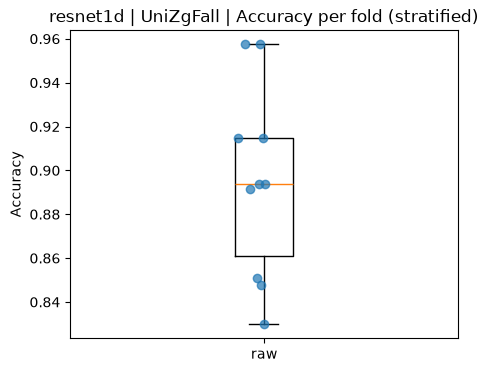

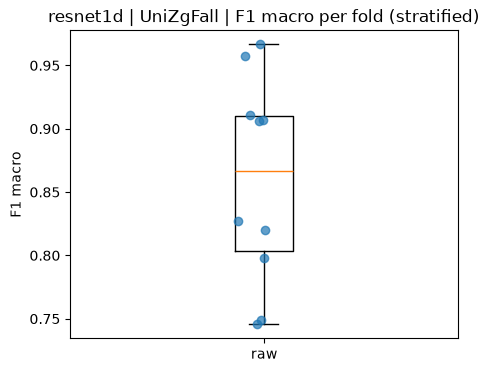

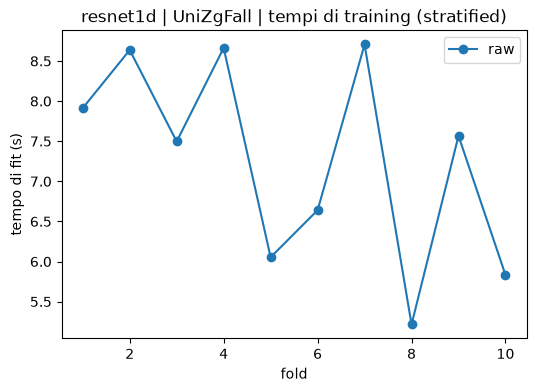

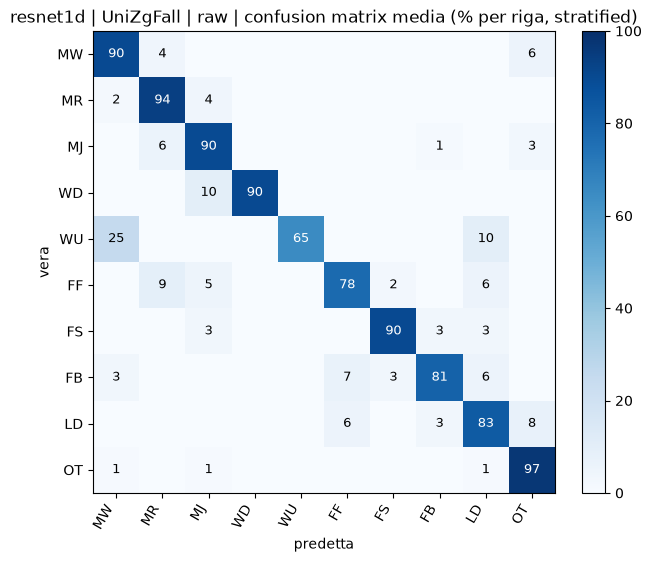

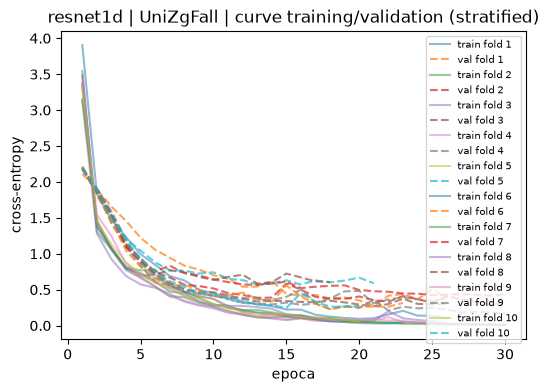

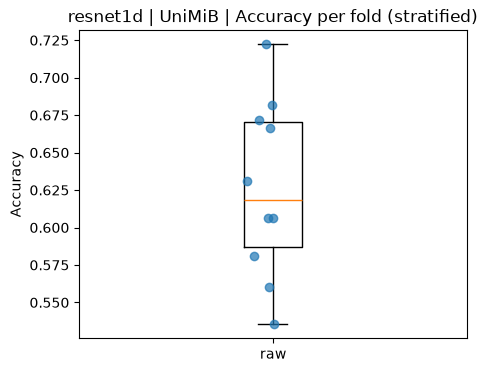

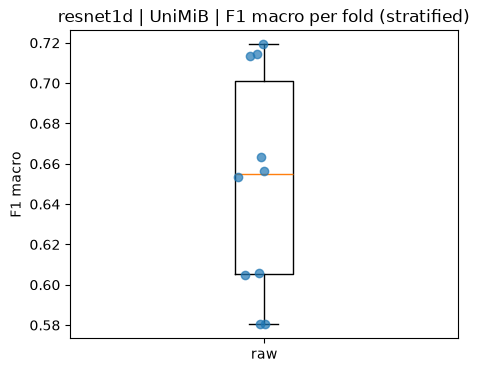

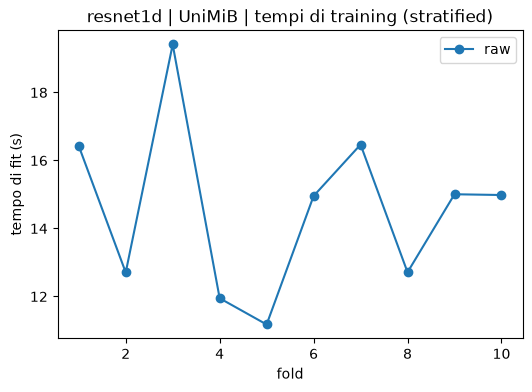

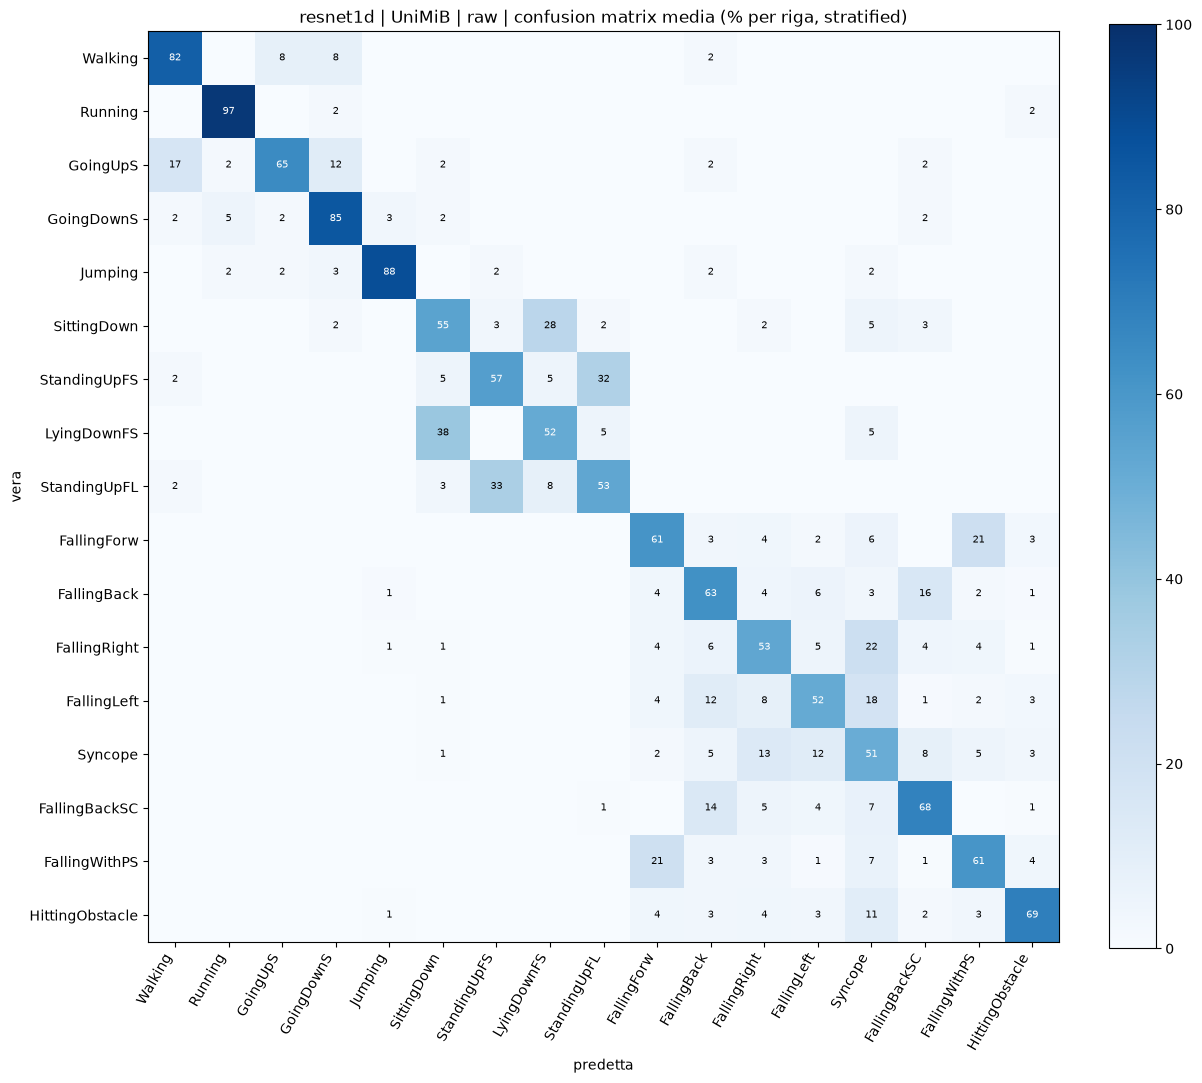

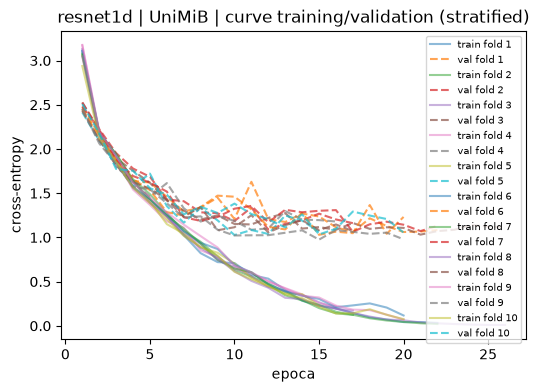

In [4]:
adv.plot_all(MODEL)